Testing CLT and Standard Error on Basket Sizes

n=  5 observed SD of means = 3.347, sigma/sqrt(n) = 3.365
n= 30 observed SD of means = 1.362, sigma/sqrt(n) = 1.374
n=300 observed SD of means = 0.436, sigma/sqrt(n) = 0.434


<function matplotlib.pyplot.show(close=None, block=None)>

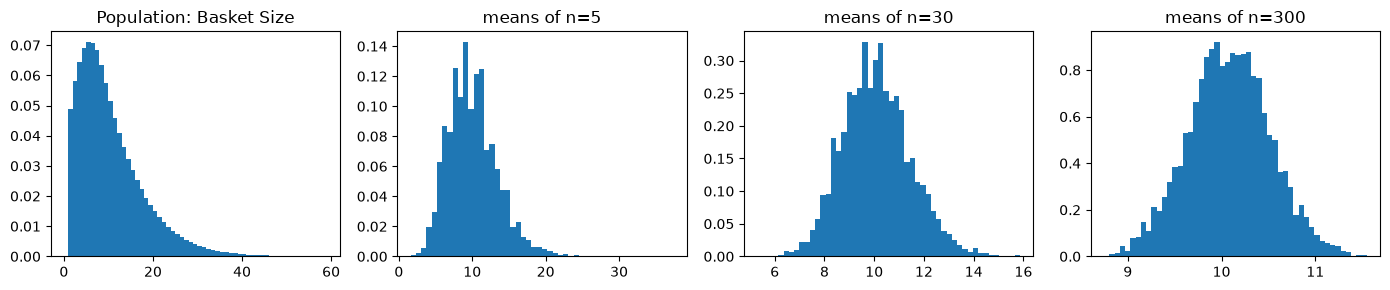

In [1]:
import duckdb, numpy as np, matplotlib.pyplot as plt
con = duckdb.connect("../data/basket.duckdb", read_only=True)
sizes = con.execute("""
    SELECT COUNT(*) AS n
    FROM order_products__prior
    GROUP BY order_id
    """).df().n.values

rng = np.random.default_rng(0)
sigma =sizes.std()

fig, axes = plt.subplots(1, 4, figsize = (14,3))
axes[0].hist(sizes, bins=range(0,60), density=True)
axes[0].set_title("Population: Basket Size")
for ax, n in zip(axes[1:], [5, 30, 300]):
    means = rng.choice(sizes, size=(5000, n)).mean(axis=1)
    ax.hist(means, bins=50, density=True)
    ax.set_title(f"means of n={n}")
    print(f"n={n:>3} observed SD of means = {means.std():.3f}, sigma/sqrt(n) = {sigma/np.sqrt(n):.3f}")

plt.tight_layout()
plt.show    

Central Limit Theorem under Extreme Skew (The Long Tail)

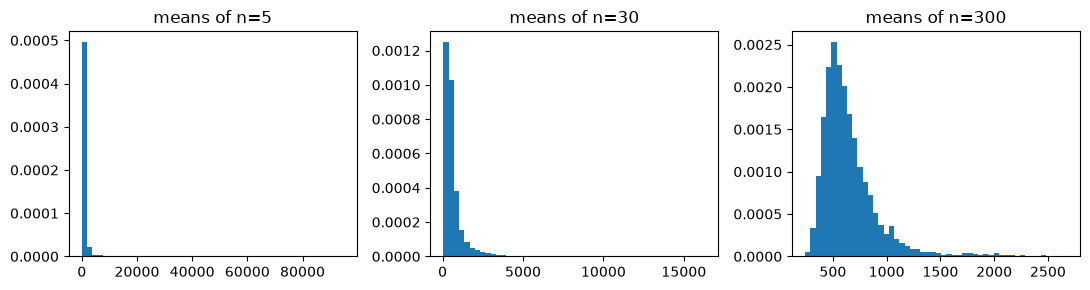

In [2]:
pop = con.execute("""
    SELECT COUNT(*) AS n FROM order_products__prior GROUP BY product_id
""").df().n.values

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, n in zip(axes, [5, 30, 300]):
    means = rng.choice(pop, size=(5000, n)).mean(axis=1)
    ax.hist(means, bins=50, density=True); ax.set_title(f"means of n={n}")
plt.tight_layout(); plt.show()